# Checking labels from meta-labeling and trend scans

Once a side is supplied, the binary label records whether that side produced a positive return by the event ending time:

$$
z_i=s_i\left(\log P_{\tau_i}-\log P_{t_i}\right),\qquad
m_i=\mathbf 1\{z_i>0\}.
$$

Here, $t_i$ and $\tau_i$ are event $i$ start and end times; $P_t$ is price; $s_i\in\{-1,1\}$ is the supplied side. $z_i$ is the side-adjusted log return; $m_i\in\{0,1\}$ is the meta-label; $\mathbf 1\{\cdot\}$ equals one when its condition is true.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
DATA_URL = 'https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'binance'
DATA_PATH = ensure_dataset(ROOT, 'binance_btcusdt')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
public_columns = ['Open time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Close time', 'Quote volume', 'Trades', 'Buyer base volume', 'Buyer quote volume', 'Unused']
raw = pd.read_csv(DATA_PATH, compression='zip', header=None, names=public_columns, nrows=None)
raw['time'] = pd.to_datetime(raw['Open time'], unit='ms', utc=True).dt.tz_convert(None)
raw = raw.rename(columns={'Close': 'close', 'Volume': 'volume', 'Quote volume': 'quote_volume', 'Trades': 'trades'})
raw = raw.sort_values('time').drop_duplicates('time').reset_index(drop=True)
from RiskLabAI.data.labeling import calculate_t_value_linear_regression, cusum_filter_events_dynamic_threshold, daily_volatility_with_log_returns, find_trend_using_trend_scanning, meta_labeling, triple_barrier, vertical_barrier
FIGURES = ROOT / 'outputs' / 'figures' / '06_financial_labels'
TABLES = ROOT / 'outputs' / 'tables' / '06_financial_labels'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
raw = raw.sort_values('time').dropna(subset=['time', 'close']).drop_duplicates('time').reset_index(drop=True)
close = pd.Series(raw['close'].to_numpy(dtype=float), index=pd.DatetimeIndex(raw['time']), name='Price')
log_price = np.log(close)
volatility = daily_volatility_with_log_returns(close, span=100)
event_times = cusum_filter_events_dynamic_threshold(log_price, (2.0 * volatility).dropna())
final_times = vertical_barrier(close, event_times, number_days=1)
prior_return = log_price - log_price.shift(60)
sides = np.sign(prior_return.reindex(event_times)).replace(0.0, np.nan).dropna()
event_times = sides.index.intersection(final_times.index).intersection(volatility.dropna().index)
sides = sides.reindex(event_times)
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Binary Meta-Labels

In [2]:
side_events = pd.DataFrame({"End Time": final_times.reindex(event_times), "Base Width": volatility.reindex(event_times), "Side": sides}, index=event_times).dropna()
touched = triple_barrier(close, side_events, [1.0, 1.0], list(side_events.index))
completed = side_events.copy()
completed["End Time"] = touched["End Time"]
meta_labels = meta_labeling(completed, close)

meta_summary = meta_labels.groupby("Label").agg(Events=("Label", "size"), Middle_signed_log_return=("Return", "median"), Mean_signed_log_return=("Return", "mean")).reset_index()
meta_summary.columns = ["Meta-label", "Events", "Middle signed log return", "Mean signed log return"]
meta_summary["Share"] = meta_summary["Events"] / len(meta_labels)
save_table(meta_summary, "meta_label_summary", "Binary outcomes after applying a side chosen from the preceding hour.", "tab:meta-label-summary", float_format="%.6f", fit=True)
display(meta_summary.round(6))

,Meta-label,Events,Middle signed log return,Mean signed log return,Share
0,0,240,-0.010140,-0.011316,0.456274
1,1,286,0.010046,0.011463,0.543726


## Rare-Label Check

A label is retained only when its observed share reaches the chosen minimum share:

$$
\widehat p_{\ell}=\frac{n_{\ell}}{n},\qquad
\mathcal L_{\eta}=\{\ell:\widehat p_{\ell}\geq\eta\}.
$$

Here, $\ell$ is a label; $n_{\ell}$ is its event count; $n$ is the total event count. $\widehat p_{\ell}$ is the observed share of label $\ell$; $\eta\in[0,1]$ is the minimum share; $\mathcal L_{\eta}$ is the retained label set.

,Data,Label,Count before,Share before,Count after,Retained
0,Public meta-labels,0,240,0.456274,240,Yes
1,Public meta-labels,1,286,0.543726,286,Yes
2,Controlled labels,-1,4,0.040000,0,No
3,Controlled labels,0,21,0.210000,21,Yes
4,Controlled labels,1,75,0.750000,75,Yes


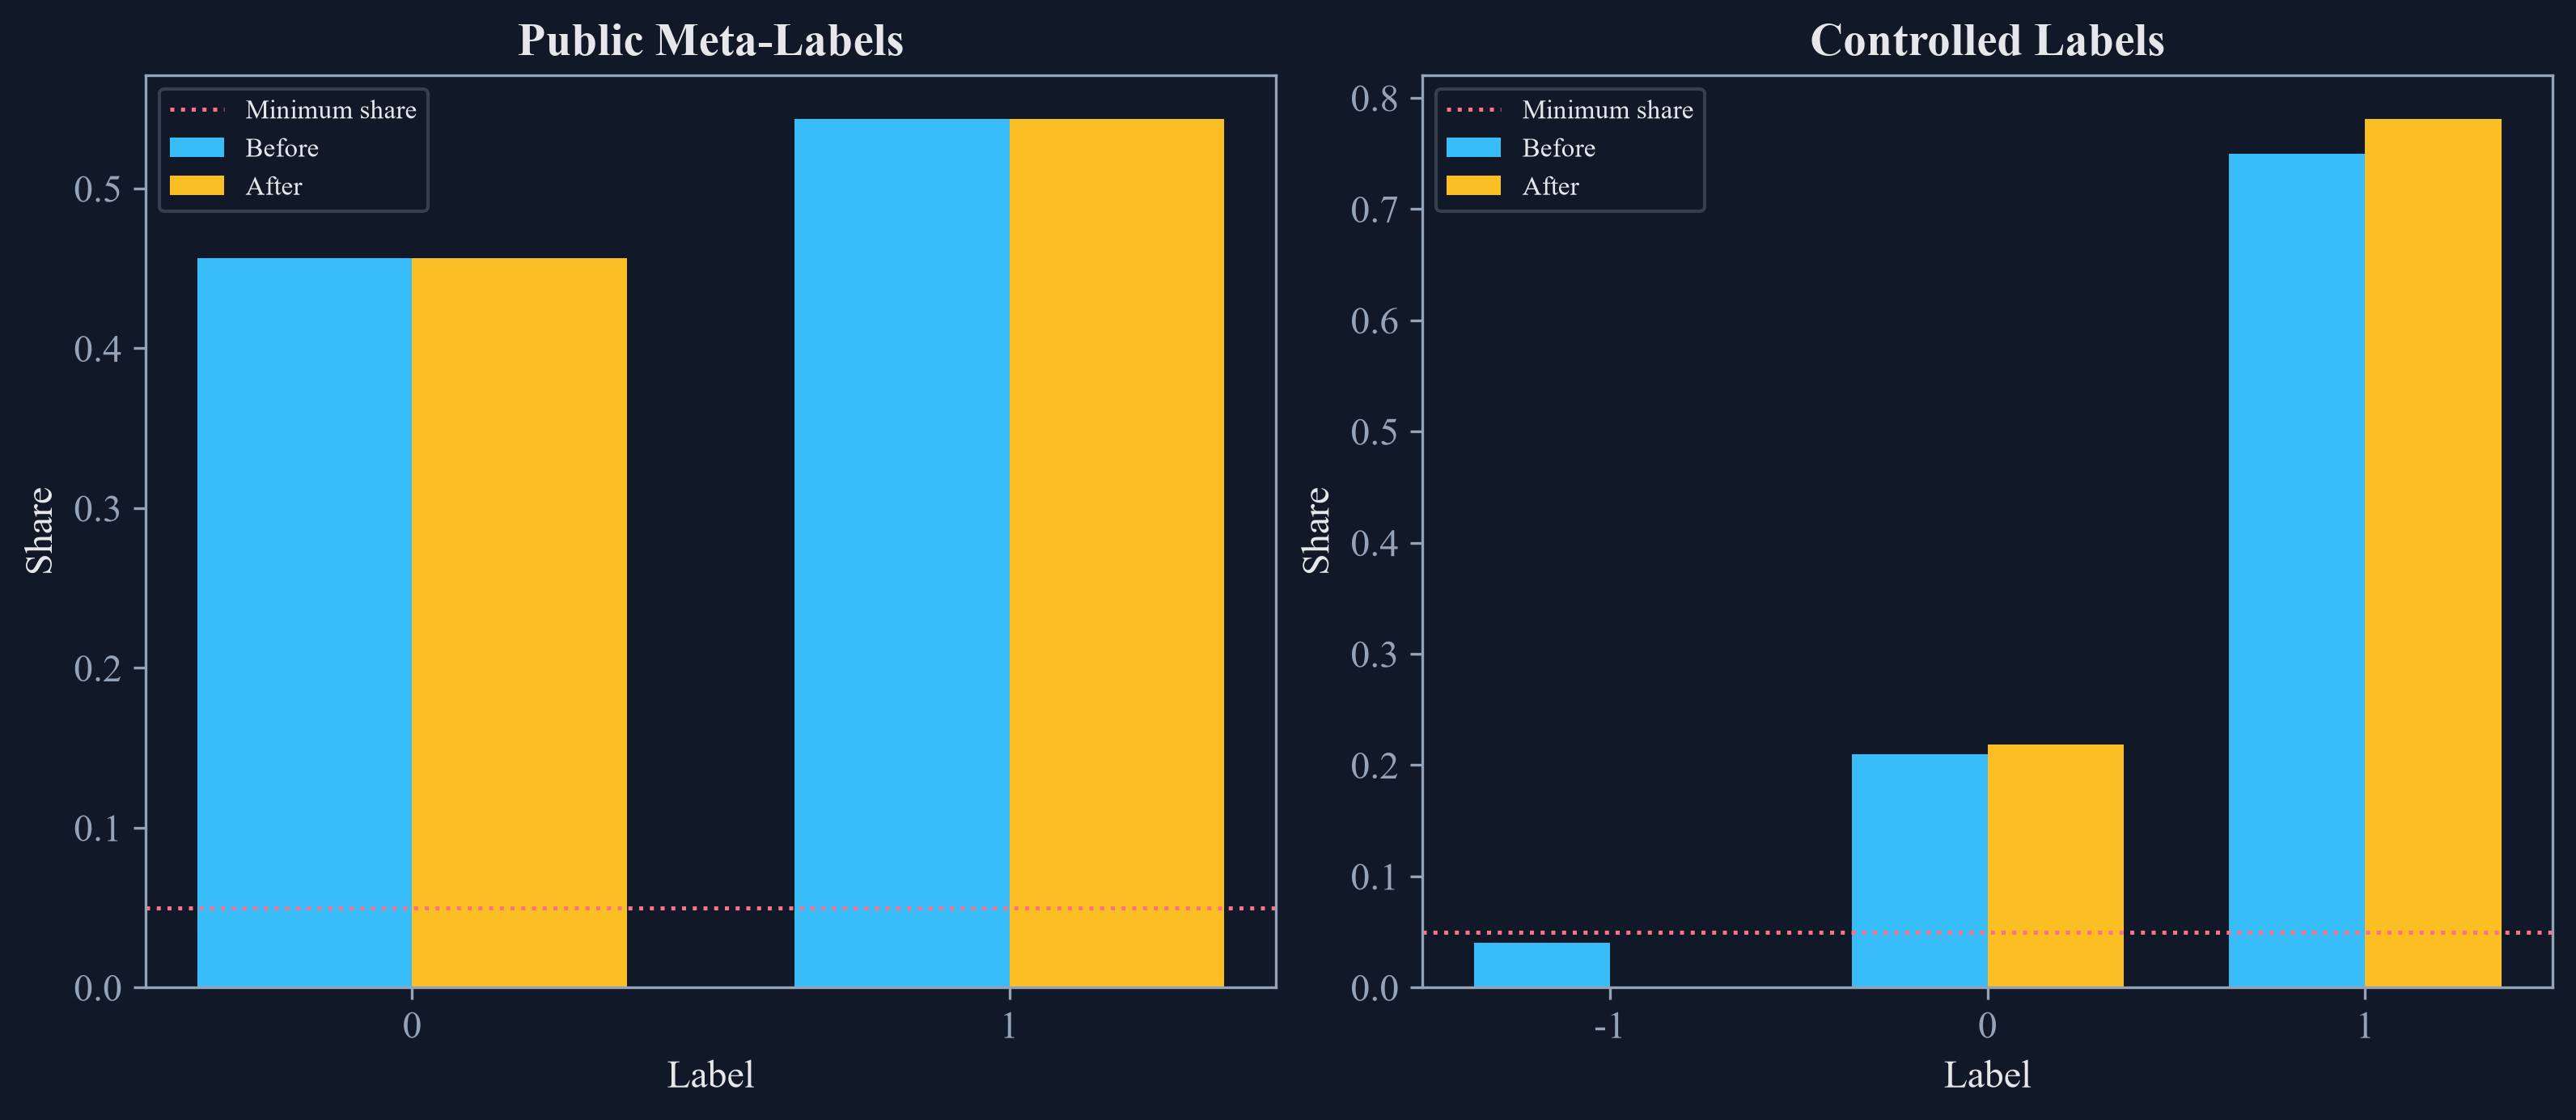

In [3]:
def filter_rare_labels(frame, label_column, minimum_share):
    shares = frame[label_column].value_counts(normalize=True)
    retained = shares[shares >= minimum_share].index
    return frame[frame[label_column].isin(retained)].copy()

minimum_share = 0.05
public_label_frame = meta_labels[["Label"]].copy()
controlled_label_frame = pd.DataFrame({"Label": np.repeat([-1.0, 0.0, 1.0], [4, 21, 75])})
public_filtered = filter_rare_labels(public_label_frame, "Label", minimum_share)
controlled_filtered = filter_rare_labels(controlled_label_frame, "Label", minimum_share)
rare_label_rows = []
for dataset_name, before, after in [("Public meta-labels", public_label_frame, public_filtered), ("Controlled labels", controlled_label_frame, controlled_filtered)]:
    labels_seen = sorted(before["Label"].unique())
    for label in labels_seen:
        before_count = int((before["Label"] == label).sum())
        after_count = int((after["Label"] == label).sum())
        rare_label_rows.append({"Data": dataset_name, "Label": label, "Count before": before_count, "Share before": before_count / len(before), "Count after": after_count, "Retained": "Yes" if after_count > 0 else "No"})
rare_label_summary = pd.DataFrame(rare_label_rows)
save_table(rare_label_summary, "rare_label_summary", "A five-percent rare-label rule applied to public and controlled labels.", "tab:chapter5-rare-labels", fit=True)
display(rare_label_summary.round(6))

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), constrained_layout=True)
for axis, title, before, after in [(axes[0], "Public Meta-Labels", public_label_frame, public_filtered), (axes[1], "Controlled Labels", controlled_label_frame, controlled_filtered)]:
    labels_seen = sorted(before["Label"].unique())
    before_share = before["Label"].value_counts(normalize=True).reindex(labels_seen, fill_value=0.0)
    after_share = after["Label"].value_counts(normalize=True).reindex(labels_seen, fill_value=0.0)
    positions = np.arange(len(labels_seen))
    width = 0.36
    axis.bar(positions - width / 2, before_share, width=width, color=palette["cyan"], label="Before")
    axis.bar(positions + width / 2, after_share, width=width, color=palette["amber"], label="After")
    axis.axhline(minimum_share, color=palette["rose"], linestyle=":", linewidth=1.2, label="Minimum share")
    axis.set_xticks(positions, [str(int(value)) for value in labels_seen])
    axis.set_xlabel("Label")
    axis.set_ylabel("Share")
    axis.set_title(title)
    axis.legend(fontsize=8)
figure.savefig(FIGURES / "rare_label_filtering.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "rare_label_filtering.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "rare_label_filtering.png")))
plt.close(figure)

## Trend Scanning

For each event and each forward length, a straight line is fitted to price and the slope is measured relative to its estimated uncertainty:

$$
P_{t_i+j}=\beta_{0,i,L}+\beta_{1,i,L}j+\varepsilon_{i,j},\qquad
T_{i,L}=\frac{\widehat\beta_{1,i,L}}{\operatorname{SE}(\widehat\beta_{1,i,L})}.
$$

Here, $t_i$ is event $i$ start; $j=0,\ldots,L-1$ counts observations; $L$ is a candidate forward length. $\beta_{0,i,L}$ is the intercept; $\beta_{1,i,L}$ is the slope; $\varepsilon_{i,j}$ is the residual; $T_{i,L}$ is the slope t-value. $\widehat\beta_{1,i,L}$ is the fitted slope and $\operatorname{SE}(\widehat\beta_{1,i,L})$ is its standard error.

The selected length has the strongest absolute linear trend, and its sign becomes the trend label:

$$
L_i^*=\arg\max_{L\in\mathcal L}|T_{i,L}|,\qquad
q_i=\operatorname{sign}(T_{i,L_i^*}).
$$

Here, $\mathcal L$ is the chosen set of forward lengths; $L_i^*$ is the selected length for event $i.$ $T_{i,L}$ is the slope t-value for length $L$; $q_i\in\{-1,0,1\}$ is the trend label; $\arg\max$ selects the largest absolute t-value.

In [4]:
candidate_events = completed.index[:240]
span = (12, 73)
trends = find_trend_using_trend_scanning(candidate_events, close, span)

best_records = []
for start in trends.index:
    location = close.index.get_loc(start)
    values = []
    for length in range(*span):
        window = close.iloc[location:location + length]
        values.append((length, calculate_t_value_linear_regression(window)))
    finite_values = [(length, value) for length, value in values if np.isfinite(value)]
    if finite_values:
        best_length, best_value = max(finite_values, key=lambda pair: abs(pair[1]))
    else:
        best_length, best_value = values[0]
    best_records.append({"Event time": start, "Selected length": best_length, "Independent t-value": best_value})
best_horizons = pd.DataFrame(best_records).set_index("Event time")
trend_results = trends.join(best_horizons)
trend_results["Absolute t-value"] = trend_results["t-Value"].astype(float).abs()

trend_summary = trend_results.groupby("Trend").agg(Events=("Trend", "size"), Middle_selected_length=("Selected length", "median"), Middle_absolute_t_value=("Absolute t-value", "median")).reset_index()
trend_summary.columns = ["Trend label", "Events", "Middle selected length", "Middle absolute t-value"]
trend_summary["Share"] = trend_summary["Events"] / len(trend_results)
save_table(trend_summary, "trend_label_summary", "Trend labels, selected forward lengths, and t-value magnitudes.", "tab:trend-label-summary", float_format="%.4f", fit=True)
display(trend_summary.round(4))

,Trend label,Events,Middle selected length,Middle absolute t-value,Share
0,-1,112,49,9.8146,0.4667
1,1,128,54.5,11.6149,0.5333


## Label Checks

,Meta-label,Trend disagrees with side,Trend agrees with side
0,0,88,19
1,1,30,103


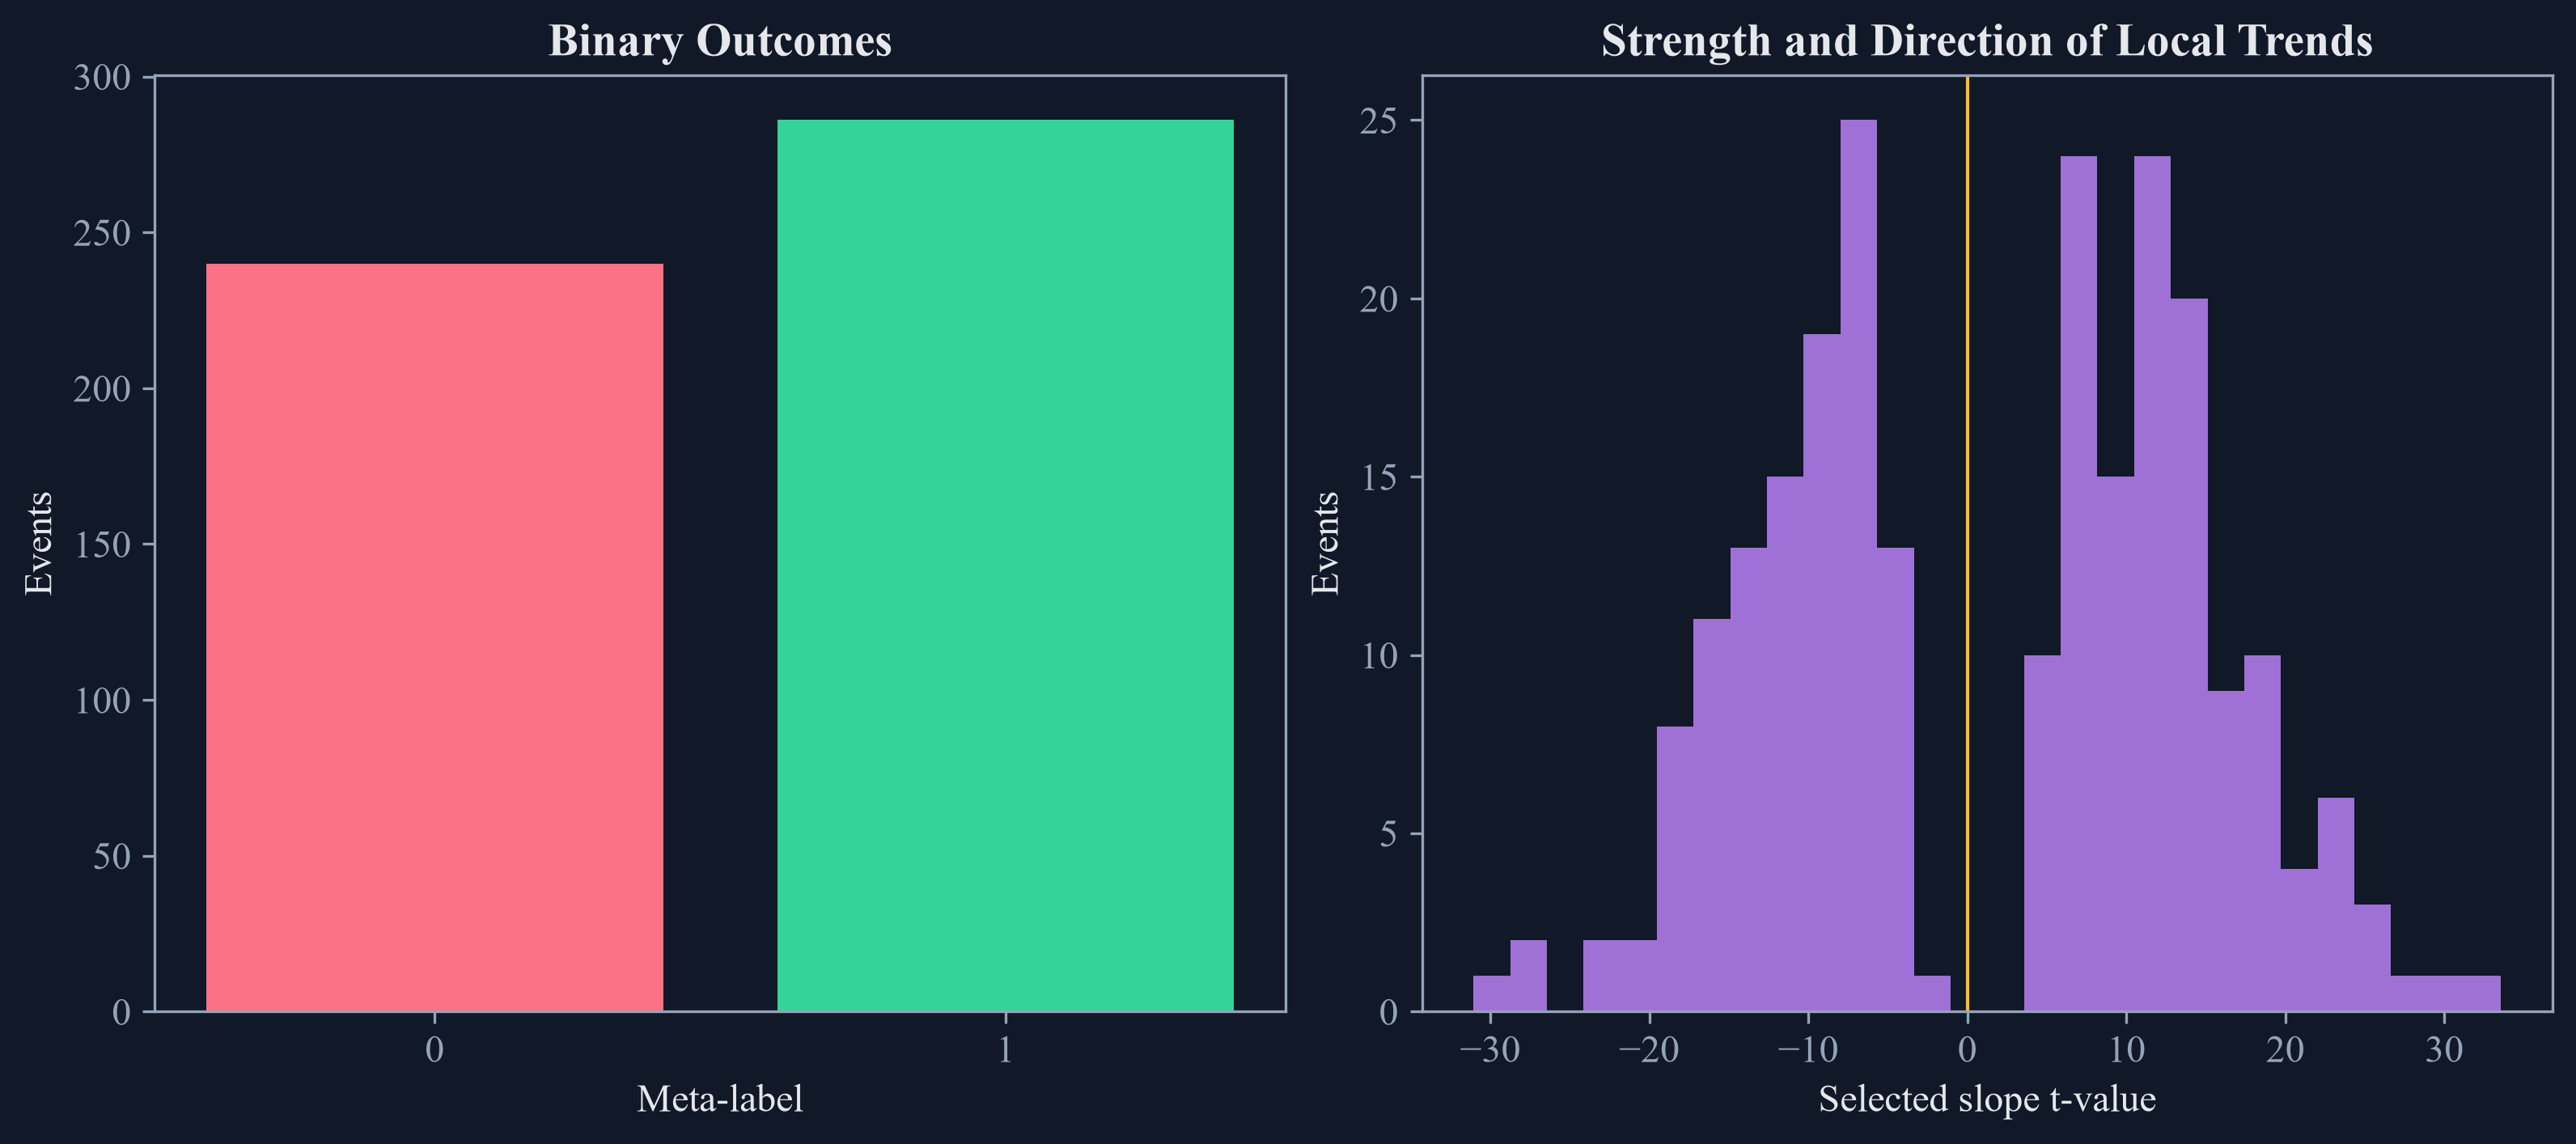

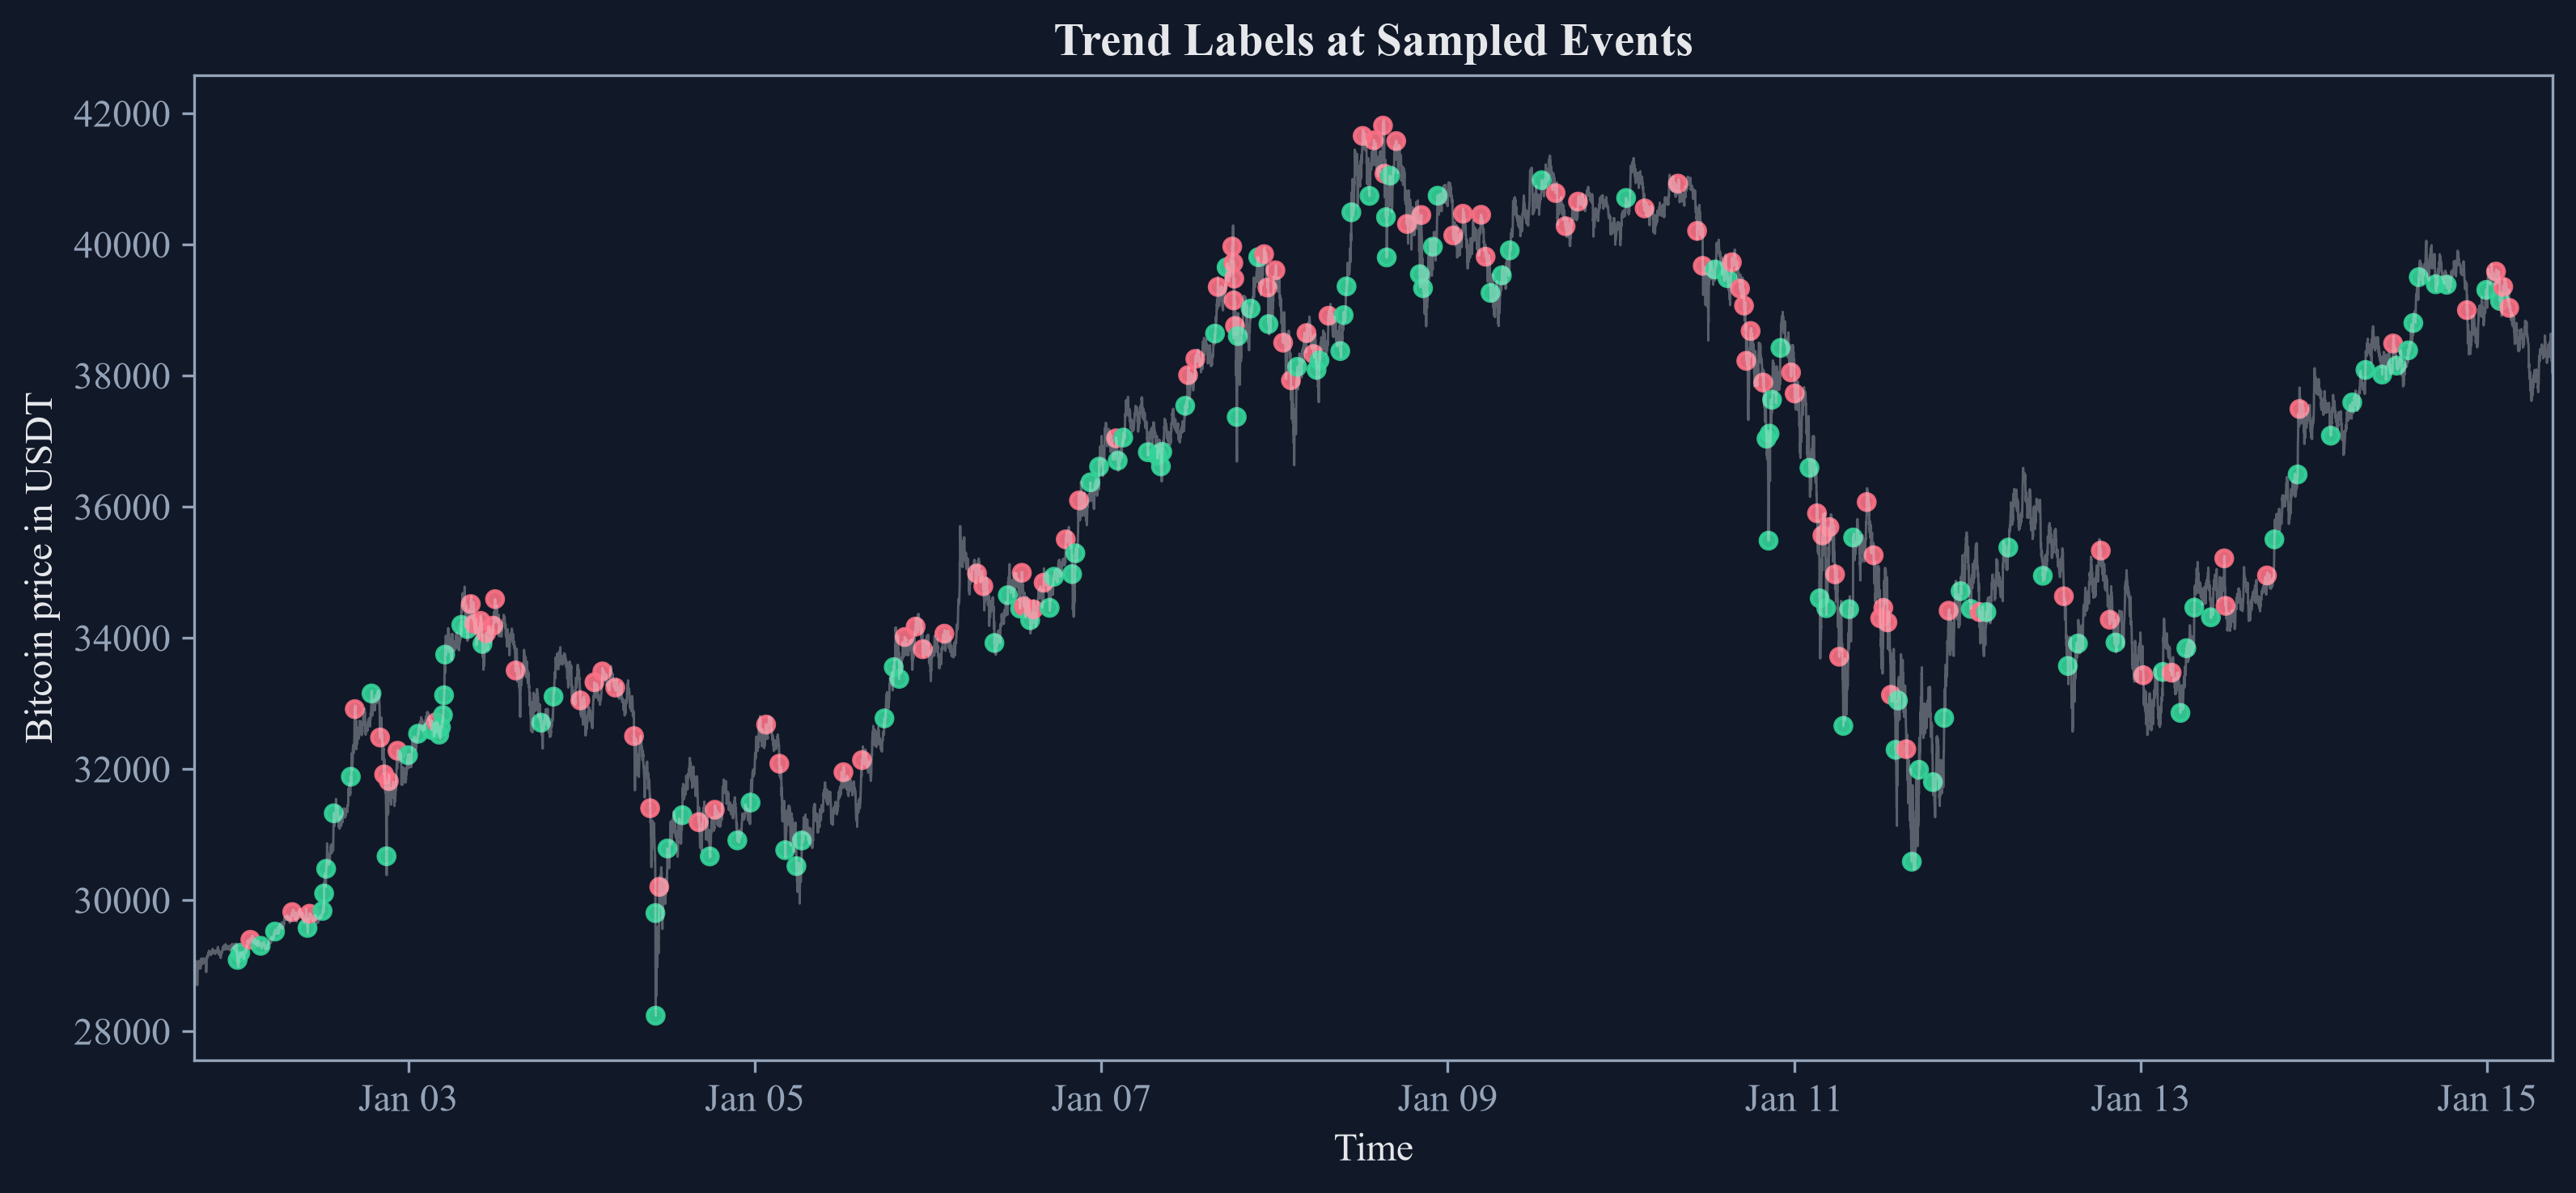

In [5]:
common = meta_labels.join(trend_results[["Trend", "Selected length", "t-Value"]], how="inner")
common["Trend agrees with supplied side"] = np.where(common["Trend"] == common["Side"], "Yes", "No")
comparison = pd.crosstab(common["Meta-label" if "Meta-label" in common.columns else "Label"], common["Trend agrees with supplied side"]).reset_index()
comparison = comparison.rename(columns={"Label": "Meta-label"})
for column in ["No", "Yes"]:
    if column not in comparison:
        comparison[column] = 0
comparison = comparison[["Meta-label", "No", "Yes"]]
comparison.columns = ["Meta-label", "Trend disagrees with side", "Trend agrees with side"]
save_table(comparison, "label_comparison", "Meta-label outcomes compared with the direction of the selected local trend.", "tab:label-comparison", float_format="%.0f", fit=False)
display(comparison)

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), constrained_layout=True)
label_counts = meta_labels["Label"].value_counts().sort_index()
axes[0].bar([str(int(value)) for value in label_counts.index], label_counts.values, color=[palette["rose"], palette["green"]][:len(label_counts)])
axes[0].set_xlabel("Meta-label")
axes[0].set_ylabel("Events")
axes[0].set_title("Binary Outcomes")
axes[1].hist(trend_results["t-Value"].astype(float), bins=28, color=palette["violet"], alpha=0.82)
axes[1].axvline(0.0, color=palette["amber"], linewidth=1.0)
axes[1].set_xlabel("Selected slope t-value")
axes[1].set_ylabel("Events")
axes[1].set_title("Strength and Direction of Local Trends")
figure.savefig(FIGURES / "label_distributions.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "label_distributions.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "label_distributions.png")))
plt.close(figure)

figure, axis = plt.subplots(figsize=(10.5, 4.8), constrained_layout=True)
trend_colors = np.where(trend_results["Trend"].astype(float) > 0, palette["green"], palette["rose"])
trend_view_start = trend_results.index.min() - pd.Timedelta(hours=6)
trend_view_end = trend_results.index.max() + pd.Timedelta(hours=6)
axis.plot(close.loc[trend_view_start:trend_view_end].index, close.loc[trend_view_start:trend_view_end], color=palette["text"], alpha=0.35, linewidth=0.7)
axis.scatter(trend_results.index, close.reindex(trend_results.index), c=trend_colors, s=24, alpha=0.9)
axis.set_xlabel("Time")
axis.set_ylabel("Bitcoin price in USDT")
axis.set_title("Trend Labels at Sampled Events")
axis.set_xlim(trend_view_start, trend_view_end)
axis.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
figure.savefig(FIGURES / "trend_scanning_labels.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "trend_scanning_labels.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "trend_scanning_labels.png")))
plt.close(figure)

## Tests

In [6]:
positive_line = pd.Series([1.0, 2.0, 3.0, 4.0, 5.0])
negative_line = pd.Series([5.0, 4.0, 3.0, 2.0, 1.0])
flat_line = pd.Series([2.0, 2.0, 2.0, 2.0, 2.0])
assert np.isposinf(calculate_t_value_linear_regression(positive_line))
assert np.isneginf(calculate_t_value_linear_regression(negative_line))
assert np.isnan(calculate_t_value_linear_regression(flat_line))
assert set(meta_labels["Label"].unique()).issubset({0.0, 1.0})
assert set(trend_results["Trend"].astype(float).unique()).issubset({-1.0, 0.0, 1.0})
assert len(meta_labels) > 0
assert len(trend_results) > 0
assert np.all(np.isin(completed["Side"], [-1.0, 1.0]))
assert np.allclose(trend_results["t-Value"].astype(float), trend_results["Independent t-value"].astype(float), rtol=1.0e-10, atol=1.0e-10)
assert trend_results["Selected length"].between(span[0], span[1] - 1).all()
assert meta_summary["Events"].sum() == len(meta_labels)
assert trend_summary["Events"].sum() == len(trend_results)
assert comparison[["Trend disagrees with side", "Trend agrees with side"]].to_numpy().sum() == len(common)
assert np.isclose(meta_summary["Share"].sum(), 1.0)
assert np.isclose(trend_summary["Share"].sum(), 1.0)
assert len(public_filtered) == len(public_label_frame)
assert len(controlled_filtered) == 96
assert -1.0 not in controlled_filtered["Label"].unique()
assert rare_label_summary.loc[(rare_label_summary["Data"] == "Controlled labels") & (rare_label_summary["Label"] == -1.0), "Retained"].iloc[0] == "No"
assert (FIGURES / "rare_label_filtering.pdf").is_file()
assert (TABLES / "rare_label_summary.tex").is_file()